# Bayesian estimation of age effects with Metropolis–Hastings

This example samples the posterior of sex-specific age effects on the interference parameter
$\nu$ with a random-walk Metropolis–Hastings sampler. Each meiosis has its own $\nu$, set by the
sex and age of its parent:

$$
\log \nu_i = \alpha_{s} + \beta_{s}\, z_i, \qquad z_i = (\text{age}_i - 30) / 10,
$$

with $s \in \{\text{maternal}, \text{paternal}\}$. The escape fraction $p$ is shared by all
meioses. The five parameters $\theta = (\alpha_\text{mat}, \alpha_\text{pat}, \beta_\text{mat},
\beta_\text{pat}, \operatorname{logit} p)$ have independent normal priors:

| Parameter | Prior | Meaning |
|---|---|---|
| $\alpha_s$ | $N(\log 4, 1)$ | $\log \nu$ at age 30 |
| $\beta_s$ | $N(0, 0.5^2)$ | age effect: change in $\log \nu$ per decade |
| $\operatorname{logit} p$ | $N(\operatorname{logit} 0.05, 1)$ | escape fraction |

The likelihood is the per-meiosis version: `loglik_fast` receives one $\nu$ per meiosis.

In [1]:
import time

import matplotlib.pyplot as plt
import numpy as np
from scipy.optimize import minimize
from scipy.special import expit, logit
from scipy.stats import norm
from tqdm import tqdm

from cointf import Meioses, loglik_fast, simulate_meiosis

## Data

300 mothers and 300 fathers aged 20 to 45, each with 3 to 7 offspring: about 3,000 meioses of one
chromosome (1.9 M in females, 1.3 M in males). In truth maternal $\nu$ falls with age
($\beta_\text{mat} = -0.25$ per decade) and paternal $\nu$ does not depend on age
($\beta_\text{pat} = 0$).

In [2]:
rng = np.random.default_rng(11)
sexes = ["maternal", "paternal"]
n_parents = 300                                   # per sex

parent_sex = np.repeat([0, 1], n_parents)         # 0 = maternal, 1 = paternal
parent_age = rng.integers(20, 46, size=2 * n_parents).astype(float)
n_offspring = rng.integers(3, 8, size=2 * n_parents)
map_length = np.array([1.9, 1.3])                 # Morgans, by sex

alpha_true, beta_true, p_true = np.log([4.0, 5.0]), np.array([-0.25, 0.0]), 0.05
theta_true = np.array([*alpha_true, *beta_true, logit(p_true)])

parent_z = (parent_age - 30) / 10
nu_parent = np.exp(alpha_true[parent_sex] + beta_true[parent_sex] * parent_z)
parent = np.repeat(np.arange(2 * n_parents), n_offspring)
data = [simulate_meiosis(map_length[parent_sex[j]], nu_parent[j], p_true, rng) for j in parent]

# Covariates of each meiosis, inherited from its parent.
s, z = parent_sex[parent], parent_z[parent]
mz = Meioses(data, map_length[s])
print(mz)

Meioses(M=2985, crossovers=4738, max_count=6)


## Log-posterior

In [3]:
names = ["alpha_mat", "alpha_pat", "beta_mat", "beta_pat", "logit_p"]
prior_mean = np.array([np.log(4.0), np.log(4.0), 0.0, 0.0, logit(0.05)])
prior_sd = np.array([1.0, 1.0, 0.5, 0.5, 1.0])


def log_posterior(theta):
    nu = np.exp(theta[s] + theta[2 + s] * z)      # one nu per meiosis
    loglik = loglik_fast(mz, None, nu=nu, p=expit(theta[4]))
    return loglik + norm.logpdf(theta, prior_mean, prior_sd).sum()


t0 = time.perf_counter()
lp_true = log_posterior(theta_true)
print(f"log-posterior at the truth: {lp_true:.2f}  ({1e3 * (time.perf_counter() - t0):.0f} ms per evaluation)")

log-posterior at the truth: -4315.57  (9 ms per evaluation)


## Proposal

A random-walk sampler mixes well when its proposal has roughly the shape of the posterior. A
simple way to get that shape is the Laplace approximation: find the posterior mode, take the
inverse Hessian of the negative log-posterior there, and scale it by $2.38^2 / d$ for $d$
parameters, the classical optimum for a Gaussian target.

In [4]:
def hessian(f, x, h=1e-3):
    x = np.asarray(x, dtype=float)
    k = x.size
    H = np.empty((k, k))
    E = np.eye(k) * h
    for i in range(k):
        for j in range(k):
            H[i, j] = (f(x + E[i] + E[j]) - f(x + E[i] - E[j])
                       - f(x - E[i] + E[j]) + f(x - E[i] - E[j])) / (4 * h * h)
    return H


neg_lp = lambda theta: -log_posterior(theta)
mode = minimize(neg_lp, x0=prior_mean, method="BFGS").x
laplace_cov = np.linalg.inv(hessian(neg_lp, mode))
proposal_chol = np.linalg.cholesky(2.38**2 / mode.size * laplace_cov)
print("posterior mode:", ", ".join(f"{n} = {v:.3f}" for n, v in zip(names, mode)))

posterior mode: alpha_mat = 1.280, alpha_pat = 1.677, beta_mat = -0.244, beta_pat = -0.016, logit_p = -2.824


## Sampler

Each step proposes $\theta' = \theta + \epsilon$ with $\epsilon \sim N(0, \Sigma)$ and accepts it
with probability $\min\{1, \pi(\theta') / \pi(\theta)\}$. The proposal is symmetric, so no
Hastings correction is needed. The chain starts from a random draw around the mode. A
`tqdm` progress bar shows the running acceptance rate.

In [5]:
def metropolis(log_target, start, chol, n_iter, rng):
    d = start.size
    chain = np.empty((n_iter, d))
    theta, lp = start, log_target(start)
    accepted = 0
    progress = tqdm(range(n_iter), desc="sampling", mininterval=1.0)
    for i in progress:
        proposal = theta + chol @ rng.standard_normal(d)
        lp_prop = log_target(proposal)
        if np.log(rng.uniform()) < lp_prop - lp:
            theta, lp = proposal, lp_prop
            accepted += 1
        chain[i] = theta
        if i % 100 == 99:
            progress.set_postfix(acceptance=f"{accepted / (i + 1):.2f}", refresh=False)
    return chain, accepted / n_iter


n_iter, burn_in = 6000, 1000
start = mode + np.linalg.cholesky(laplace_cov) @ rng.standard_normal(mode.size)
t0 = time.perf_counter()
chain, acceptance = metropolis(log_posterior, start, proposal_chol, n_iter, rng)
print(f"{n_iter} iterations in {time.perf_counter() - t0:.0f} s, acceptance rate {acceptance:.2f}")
posterior = chain[burn_in:]

sampling: 100%|██████████| 6000/6000 [00:55<00:00, 108.78it/s, acceptance=0.29]


6000 iterations in 55 s, acceptance rate 0.29


## Diagnostics

Trace plots should look like stationary noise after the burn-in (shaded). The effective sample
size (ESS) estimates how many independent draws the correlated chain is worth; it uses the
autocorrelations up to the first negative one.

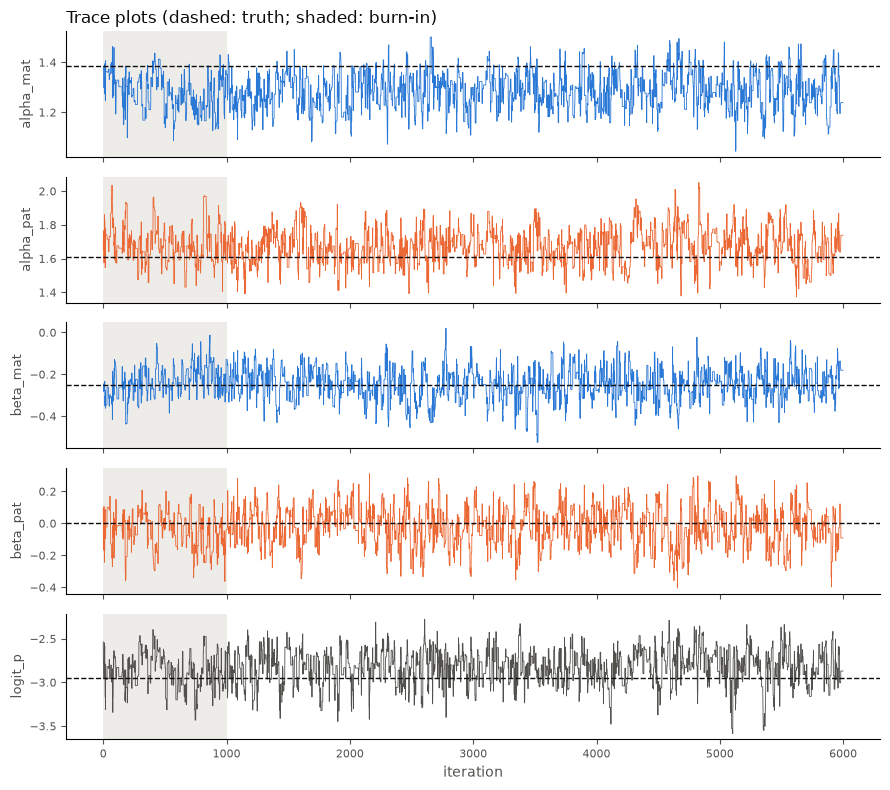

parameter       ESS
alpha_mat       336
alpha_pat       261
beta_mat        368
beta_pat        275
logit_p         324


In [6]:
def effective_sample_size(x):
    x = x - x.mean()
    n = x.size
    acf = np.correlate(x, x, mode="full")[n - 1:] / (x.var() * n)
    first_negative = np.argmax(acf[1:] < 0) + 1
    return n / (1 + 2 * acf[1:first_negative].sum())


ink, ink2, grid = "#0b0b0b", "#52514e", "#e1e0d9"
colours = ["#2a78d6", "#eb6834"]                  # maternal, paternal
trace_colour = [colours[0], colours[1], colours[0], colours[1], ink2]

fig, axes = plt.subplots(len(names), 1, figsize=(9, 8), sharex=True)
for k, ax in enumerate(axes):
    ax.axvspan(0, burn_in, color=grid, alpha=0.6, lw=0)
    ax.plot(chain[:, k], color=trace_colour[k], lw=0.6)
    ax.axhline(theta_true[k], color=ink, lw=1, ls="--")
    ax.set_ylabel(names[k], color=ink2, fontsize=9)
    ax.tick_params(colors=ink2, labelsize=8)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
axes[0].set_title("Trace plots (dashed: truth; shaded: burn-in)", color=ink, loc="left")
axes[-1].set_xlabel("iteration", color=ink2)
fig.tight_layout()
plt.show()

print(f"{'parameter':<11}{'ESS':>8}")
for k, n in enumerate(names):
    print(f"{n:<11}{effective_sample_size(posterior[:, k]):8.0f}")

## Posterior summary

In [7]:
print(f"{'parameter':<11}{'mean':>8}{'sd':>8}{'2.5%':>9}{'97.5%':>9}{'truth':>8}")
for k, n in enumerate(names):
    lo, hi = np.quantile(posterior[:, k], [0.025, 0.975])
    print(f"{n:<11}{posterior[:, k].mean():8.3f}{posterior[:, k].std():8.3f}{lo:9.3f}{hi:9.3f}{theta_true[k]:8.3f}")

p_draws = expit(posterior[:, 4])
print(f"\np: posterior mean {p_draws.mean():.3f}, 95% interval "
      f"[{np.quantile(p_draws, 0.025):.3f}, {np.quantile(p_draws, 0.975):.3f}] (truth {p_true})")

difference = posterior[:, 2] - posterior[:, 3]
for k, name in enumerate(sexes):
    print(f"P(beta_{name[:3]} < 0 | data) = {np.mean(posterior[:, 2 + k] < 0):.3f}  (from {len(posterior)} draws)")
print(f"beta_mat - beta_pat: mean {difference.mean():.3f}, 95% interval "
      f"[{np.quantile(difference, 0.025):.3f}, {np.quantile(difference, 0.975):.3f}]")

parameter      mean      sd     2.5%    97.5%   truth
alpha_mat     1.286   0.073    1.147    1.435   1.386
alpha_pat     1.674   0.103    1.471    1.882   1.609
beta_mat     -0.249   0.077   -0.407   -0.095  -0.250
beta_pat     -0.020   0.121   -0.274    0.212   0.000
logit_p      -2.824   0.198   -3.235   -2.466  -2.944

p: posterior mean 0.057, 95% interval [0.038, 0.078] (truth 0.05)
P(beta_mat < 0 | data) = 1.000  (from 5000 draws)
P(beta_pat < 0 | data) = 0.555  (from 5000 draws)
beta_mat - beta_pat: mean -0.229, 95% interval [-0.520, 0.054]


## Prior and posterior for the age effects

The posterior of each age effect is much narrower than its $N(0, 0.5^2)$ prior (gray), so the data
dominate. The maternal posterior sits well below zero; the paternal one is centred near zero.
Shown as a ratio, $e^{\beta}$ is the factor by which $\nu$ changes per decade of age.

maternal: nu changes by a factor 0.78 per decade (95% interval 0.67-0.91)
paternal: nu changes by a factor 0.98 per decade (95% interval 0.76-1.24)


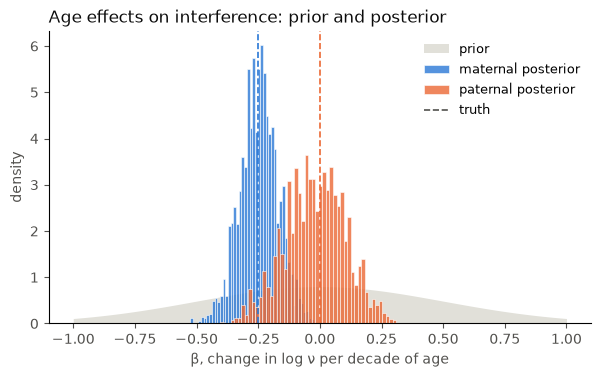

In [8]:
grid_beta = np.linspace(-1.0, 1.0, 400)
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.fill_between(grid_beta, norm.pdf(grid_beta, 0, 0.5), color=grid, lw=0, label="prior")
for k, name in enumerate(sexes):
    ax.hist(posterior[:, 2 + k], bins=50, density=True, color=colours[k], alpha=0.8,
            edgecolor="white", linewidth=0.5, label=f"{name} posterior")
    ax.axvline(beta_true[k], color=colours[k], lw=1.2, ls="--")
    ratio = np.exp(np.quantile(posterior[:, 2 + k], [0.5, 0.025, 0.975]))
    print(f"{name}: nu changes by a factor {ratio[0]:.2f} per decade (95% interval {ratio[1]:.2f}-{ratio[2]:.2f})")
ax.plot([], [], color=ink2, lw=1.2, ls="--", label="truth")
ax.set_xlabel("β, change in log ν per decade of age", color=ink2)
ax.set_ylabel("density", color=ink2)
ax.set_title("Age effects on interference: prior and posterior", color=ink, loc="left")
ax.legend(frameon=False, fontsize=9, loc="upper right")
for side in ("top", "right"):
    ax.spines[side].set_visible(False)
ax.tick_params(colors=ink2)
plt.show()

## Posterior age curves

Each posterior draw defines a curve $\nu(\text{age})$ for each sex. The bands hold the central 95%
of the curves at each age, and the dashed lines are the truth.

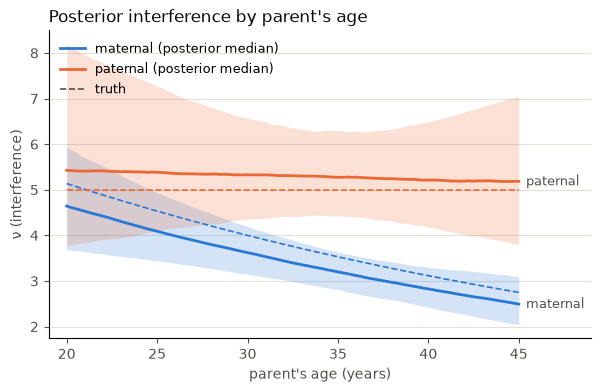

In [9]:
ages = np.linspace(20, 45, 101)
za = (ages - 30) / 10
fig, ax = plt.subplots(figsize=(7, 4))
for k, name in enumerate(sexes):
    curves = np.exp(posterior[:, k, None] + posterior[:, 2 + k, None] * za)
    lo, mid, hi = np.quantile(curves, [0.025, 0.5, 0.975], axis=0)
    ax.fill_between(ages, lo, hi, color=colours[k], alpha=0.2, lw=0)
    ax.plot(ages, mid, color=colours[k], lw=2, label=f"{name} (posterior median)")
    ax.plot(ages, np.exp(alpha_true[k] + beta_true[k] * za), color=colours[k], lw=1.2, ls="--")
    ax.text(ages[-1] + 0.4, mid[-1], name, color=ink2, fontsize=9, va="center")
ax.plot([], [], color=ink2, lw=1.2, ls="--", label="truth")
ax.set_xlim(19, 49)
ax.set_xlabel("parent's age (years)", color=ink2)
ax.set_ylabel("ν (interference)", color=ink2)
ax.set_title("Posterior interference by parent's age", color=ink, loc="left")
ax.legend(frameon=False, fontsize=9, loc="upper left")
ax.grid(axis="y", color=grid, lw=0.8)
ax.set_axisbelow(True)
for side in ("top", "right"):
    ax.spines[side].set_visible(False)
ax.tick_params(colors=ink2)
plt.show()

## Notes

- **Run time.** Each log-posterior evaluation takes about 10 ms for 3,000 meioses, so 6,000
  iterations take about a minute. Run time grows linearly with the number of meioses.
- **Checking convergence.** For real analyses, run several chains from dispersed starting points
  and compare them (for example with $\hat R$), and run longer chains if the ESS is small.
- **Age effects on $p$.** Adding $\operatorname{logit} p_i = \gamma_s + \delta_s z_i$ only changes
  `log_posterior`. Expect wide posteriors for $\delta_s$ at this sample size; see
  [the maximum-likelihood version](age_effects.ipynb).
- **Parent-level variation.** A random effect per parent, $\log \nu_j \sim N(\alpha_s + \beta_s z_j,
  \sigma^2)$, makes the model hierarchical. Individual $\nu_j$ are then only weakly identified unless
  each parent has many meioses.